# Plot Fig.1B.

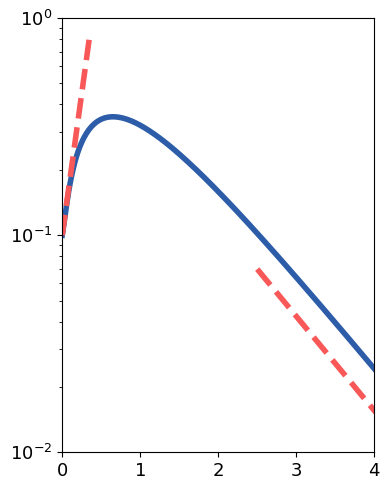

alpha= -1.0
omega= 6.016648189186455


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import scipy.linalg as la

M = np.array([[-1, 15],
              [0, -2]])

delta_x0 = np.array([0.05, 0.05 * np.sqrt(3)])
norm_delta_x0 = np.linalg.norm(delta_x0)

eigenvalues_M = la.eigvals(M)
alpha = np.max(np.real(eigenvalues_M))

M_sym = (M + M.T) / 2
eigenvalues_M_sym = la.eigvals(M_sym)
omega = np.max(np.real(eigenvalues_M_sym))

def system(t, eta):
    return M @ eta

t_span = (0, 5)
t_eval = np.linspace(t_span[0], t_span[1], 500)

sol = solve_ivp(system, t_span, delta_x0, t_eval=t_eval)

norm_eta = np.linalg.norm(sol.y, axis=0)

plt.figure(figsize=(4, 5))

plt.plot(sol.t, norm_eta, color='#2D5CA8', linewidth=4)

t_omega = np.linspace(0, 0.35, 50)
bound_omega = norm_delta_x0 * np.exp(omega * t_omega)
plt.plot(t_omega, bound_omega, color='#F85858', linestyle='--', linewidth=4)

t_alpha = np.linspace(2.5, 5, 50)
bound_alpha = 0.85 * np.exp(alpha * t_alpha)
plt.plot(t_alpha, bound_alpha, color='#F85858', linestyle='--', linewidth=4)

plt.xlim(0, 4)
plt.ylim(10**(-2), 1)

plt.yscale('log')

plt.tick_params(labelsize=13)

plt.tight_layout()
plt.savefig('non_normal.svg', format='svg', bbox_inches='tight')
plt.show()

print("alpha=", alpha)
print("omega=", omega)

# Plot Fig.2.

===== Spectral quantities =====
alpha = -1.5502952351975812
omega = -1.1464075955801454
nu    = 0.6999370000044799

===== Bound parameters =====
a1 = 0.47500000000000003
b1 = 1.425
a2 = 0.9716666666666666
b2 = 0.795
c^- = -4.5
c^+ = -1.5

===== Bounds =====
alpha <= omega <= c^+ + a1
c^+ + a1 = -1.025
nu <= b2
b2 = 0.795

===== Numerical-range approximation =====
Inner area     = 4.723307
Outer area     = 4.723402
Relative error = 2.015567e-05


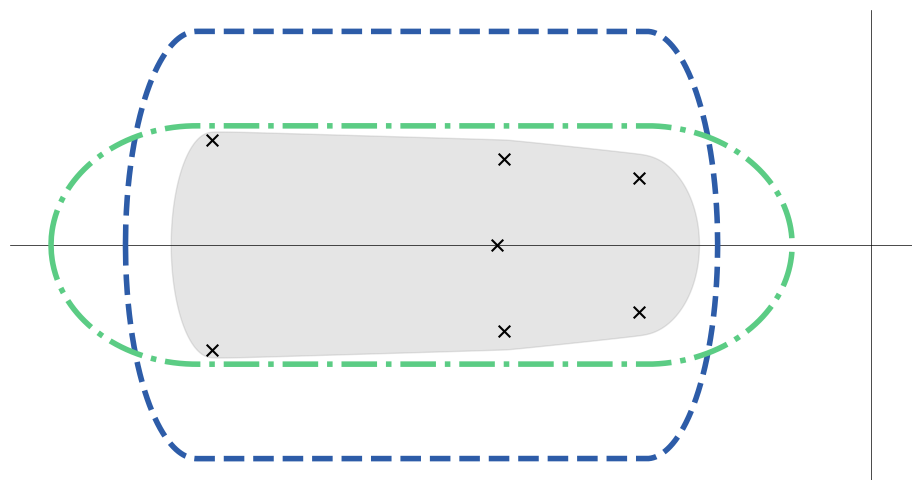

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


M = np.array([
    [-4.5,   1.0,   0.0,   0.0,   0.0,   0.1,   0.0],
    [-0.5,  -4.3,   0.0,   0.0,   0.0,   0.0,   0.0],
    [ 0.0,   0.0,  -2.5,   1.1,   0.0,   0.0,   0.0],
    [ 0.0,   0.0,  -0.3,  -2.4,   0.0,   0.0,   0.0],
    [ 0.0,   0.0,   0.0,   0.0,  -1.5,   1.0,   0.0],
    [ 0.01,  0.0,   0.01,  0.0,  -0.2,  -1.6,   0.02],
    [ 0.0,   0.0,   0.0,   0.0,   0.0,  -0.05, -2.5]
], dtype=float)

N = M.shape[0]


M_plus = (M + M.T) / 2
M_minus = (M - M.T) / 2

M_plus_off = M_plus.copy()
np.fill_diagonal(M_plus_off, 0)


eigenvalues_M = np.linalg.eigvals(M)
alpha = np.max(eigenvalues_M.real)
omega = np.max(np.linalg.eigvalsh(M_plus))
nu = np.max(np.abs(eigenvalues_M.imag))

a1_F = np.linalg.norm(M_plus_off, ord='fro')
a1_inf = np.linalg.norm(M_plus_off, ord=np.inf)
a1 = min(a1_F, a1_inf)

b2_F = np.linalg.norm(M_minus, ord='fro')
b2_inf = np.linalg.norm(M_minus, ord=np.inf)
b2 = min(b2_F, b2_inf)

connected = np.zeros((N, N), dtype=bool)

for i in range(N):
    for j in range(N):
        if i != j and (M[i, j] != 0 or M[j, i] != 0):
            connected[i, j] = True

if np.any(connected):
    if np.any(
        connected
        & np.isclose(M_plus, 0)
    ):
        b1 = np.inf

    else:
        ratio_minus_plus = np.abs(
            M_minus[connected] / M_plus[connected]
        )

        b1 = np.max(ratio_minus_plus) * a1

else:
    b1 = np.inf

if np.any(connected):
    if np.any(
        connected
        & np.isclose(M_minus, 0)
    ):
        a2 = np.inf

    else:
        ratio_plus_minus = np.abs(
            M_plus[connected] / M_minus[connected]
        )

        a2 = np.max(ratio_plus_minus) * b2

else:
    a2 = np.inf


diag_M = np.diag(M)

c_minus = np.min(diag_M)
c_plus = np.max(diag_M)


print("===== Spectral quantities =====")
print("alpha =", alpha)
print("omega =", omega)
print("nu    =", nu)

print("\n===== Bound parameters =====")
print("a1 =", a1)
print("b1 =", b1)
print("a2 =", a2)
print("b2 =", b2)
print("c^- =", c_minus)
print("c^+ =", c_plus)

print("\n===== Bounds =====")
print("alpha <= omega <= c^+ + a1")
print("c^+ + a1 =", c_plus + a1)
print("nu <= b2")
print("b2 =", b2)


def compute_S_boundary(
    a_i,
    b_i,
    c_minus,
    c_plus,
    num_points=2000
):
    """
    Boundary of

        S_i = union_{c in [c^-, c^+]}
              {z :
               ((Re z - c)/a_i)^2
               + (Im z/b_i)^2 <= 1}

    for finite positive a_i and b_i.
    """

    if not np.isfinite(a_i) or not np.isfinite(b_i):
        raise ValueError(
            "This plotting function assumes finite a_i and b_i."
        )

    if a_i <= 0 or b_i < 0:
        raise ValueError(
            "This plotting function assumes a_i > 0 and b_i >= 0."
        )

    x_values = np.linspace(
        c_minus - a_i,
        c_plus + a_i,
        num_points
    )

    y_upper = np.zeros_like(x_values)

    for k, x in enumerate(x_values):
        if x < c_minus:
            c_star = c_minus

        elif x > c_plus:
            c_star = c_plus

        else:
            c_star = x

        argument = 1 - ((x - c_star) / a_i)**2

        if argument >= 0:
            y_upper[k] = b_i * np.sqrt(argument)
        else:
            y_upper[k] = 0

    return x_values, y_upper


x_S1, y_S1 = compute_S_boundary(
    a1,
    b1,
    c_minus,
    c_plus
)

x_S2, y_S2 = compute_S_boundary(
    a2,
    b2,
    c_minus,
    c_plus
)


num_theta = 10000

thetas = np.linspace(
    0,
    2 * np.pi,
    num_theta,
    endpoint=False
)

support_values = np.zeros(num_theta)

W_inner = np.zeros(
    num_theta,
    dtype=complex
)


for k, theta in enumerate(thetas):
    H_theta = 0.5 * (
        np.exp(1j * theta) * M
        +
        np.exp(-1j * theta) * M.conj().T
    )

    eigvals_H, eigvecs_H = np.linalg.eigh(H_theta)

    u_theta = eigvecs_H[:, -1]

    support_values[k] = eigvals_H[-1]

    W_inner[k] = np.vdot(
        u_theta,
        M @ u_theta
    )

W_outer = np.zeros(
    num_theta,
    dtype=complex
)

delta_theta = 2 * np.pi / num_theta


for k in range(num_theta):

    next_k = (k + 1) % num_theta

    h_k = support_values[k]
    h_next = support_values[next_k]

    real_part = h_k

    imag_part = (
        h_k * np.cos(delta_theta)
        -
        h_next
    ) / np.sin(delta_theta)

    W_outer[k] = (
        np.exp(-1j * thetas[k])
        *
        (real_part + 1j * imag_part)
    )


W_inner_plot = np.append(
    W_inner,
    W_inner[0]
)

W_outer_plot = np.append(
    W_outer,
    W_outer[0]
)


def polygon_area(z):

    x = z.real
    y = z.imag

    return 0.5 * np.abs(
        np.sum(
            x[:-1] * y[1:]
            -
            x[1:] * y[:-1]
        )
    )


area_inner = polygon_area(W_inner_plot)
area_outer = polygon_area(W_outer_plot)

relative_error = (
    area_outer - area_inner
) / area_outer


print("\n===== Numerical-range approximation =====")
print(f"Inner area     = {area_inner:.6f}")
print(f"Outer area     = {area_outer:.6f}")
print(f"Relative error = {relative_error:.6e}")


fig, ax = plt.subplots(
    figsize=(12, 5)
)


COLOR_W = "grey"
COLOR_S1 = "#2D5CA8"
COLOR_S2 = "#5BCC84"


ax.fill(
    W_inner_plot.real,
    W_inner_plot.imag,
    color=COLOR_W,
    alpha=0.2,
    zorder=0,
    label=r'$W(\mathbf{M})$'
)


ax.plot(
    x_S1,
    y_S1,
    color=COLOR_S1,
    linestyle='--',
    linewidth=4,
    zorder=3,
    label=r'Boundary of $S_1$'
)

ax.plot(
    x_S1,
    -y_S1,
    color=COLOR_S1,
    linestyle='--',
    linewidth=4,
    zorder=3
)


ax.plot(
    x_S2,
    y_S2,
    color=COLOR_S2,
    linestyle='-.',
    linewidth=4,
    zorder=3,
    label=r'Boundary of $S_2$'
)

ax.plot(
    x_S2,
    -y_S2,
    color=COLOR_S2,
    linestyle='-.',
    linewidth=4,
    zorder=3
)


ax.scatter(
    eigenvalues_M.real,
    eigenvalues_M.imag,
    color='black',
    marker='x',
    s=70,
    zorder=5,
    label=r'Eigenvalues'
)


ax.axhline(
    0,
    color='black',
    linewidth=0.5,
    zorder=1
)

ax.axvline(
    0,
    color='black',
    linewidth=0.5,
    zorder=1
)


ax.set_aspect(
    'equal',
    adjustable='box'
)

ax.axis('off')


plt.tight_layout()

plt.savefig(
    'numerical_range_plot.svg',
    format='svg',
    bbox_inches='tight'
)

plt.show()

# Plot Fig.3.

In [ ]:
def generate_random_M(N, connectance=0.3, c_min=-10, c_max=-5):
    M = np.diag(np.random.uniform(c_min, c_max, N))

    for i in range(N):
        for j in range(i + 1, N):
            if np.random.rand() < connectance:
              M[i, j] = np.random.uniform(-3, 3)
              M[j, i] = np.random.uniform(-3, 3)
    return M

def calculate_metrics(M):
    N = M.shape[0]

    M_plus = (M + M.T) / 2
    M_minus = (M - M.T) / 2

    off_diag_mask = ~np.eye(N, dtype=bool)

    sum_sq_plus = np.sqrt(np.sum(M_plus[off_diag_mask]**2))
    max_sum_abs_plus = np.max(np.sum(np.abs(M_plus * off_diag_mask), axis=1))
    a_1 = min(sum_sq_plus, max_sum_abs_plus)

    sum_sq_minus = np.sqrt(np.sum(M_minus[off_diag_mask]**2))
    max_sum_abs_minus = np.max(np.sum(np.abs(M_minus * off_diag_mask), axis=1))
    b_2=min(sum_sq_minus, max_sum_abs_minus)

    bound_on_omega = np.max(np.diag(M)) +a_1
    bound_on_nu=b_2

    eigvals_M = np.linalg.eigvals(M)
    eigvals_M_plus = np.linalg.eigvals(M_plus)

    omega = np.max(np.real(eigvals_M_plus))
    nu = np.max(np.imag(eigvals_M))

    return bound_on_omega, omega, bound_on_nu, nu

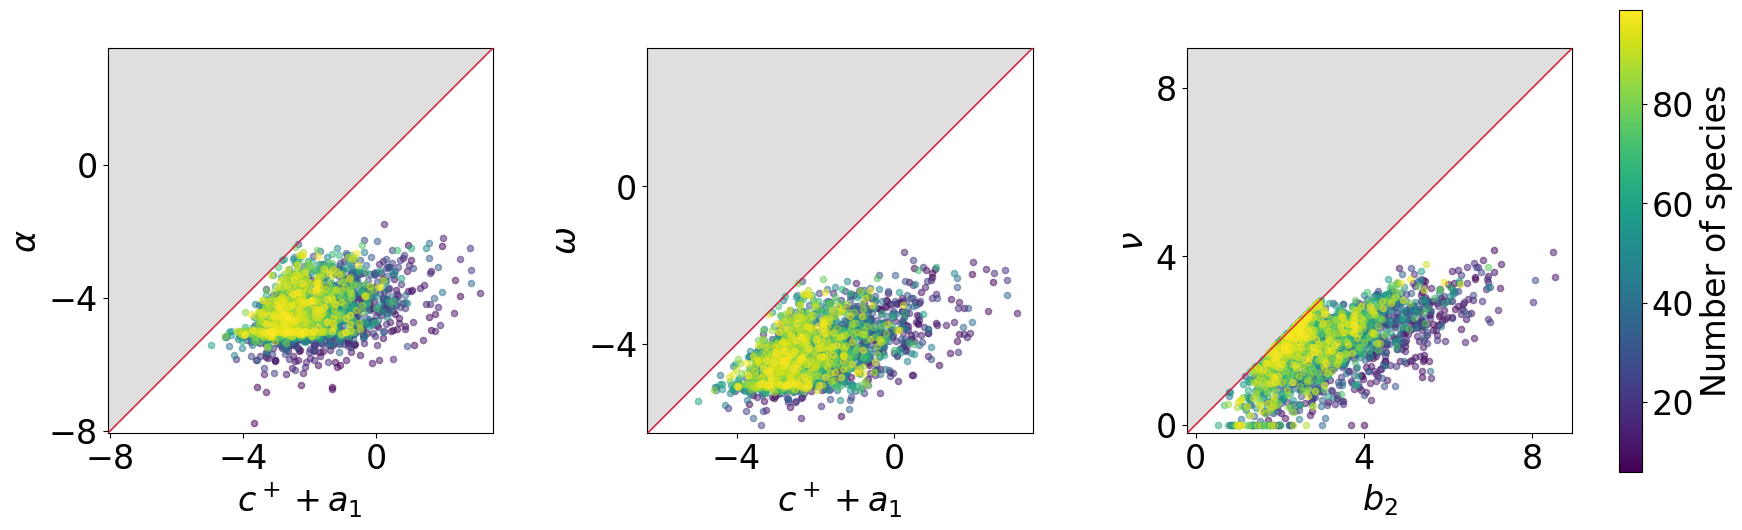

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib import cm
from matplotlib.colors import Normalize

N_values = np.arange(6, 100)

num_samples = 25
c_min = -10
c_max = -5

cmap = cm.viridis

norm = Normalize(
    vmin=np.min(N_values),
    vmax=np.max(N_values)
)

fig, (ax1, ax2, ax3) = plt.subplots(
    1,
    3,
    figsize=(20, 6)
)

fig.subplots_adjust(wspace=0.4)


np.random.seed(0)

for N in N_values:

    connectance = 20 / (N * (N - 1))

    color = cmap(norm(N))

    bound_on_alpha_list = []
    alpha_list = []

    bound_on_omega_list = []
    omega_list = []

    bound_on_nu_list = []
    nu_list = []

    for _ in range(num_samples):

        M = generate_random_M(
            N,
            connectance=connectance,
            c_min=c_min,
            c_max=c_max
        )

        eigvals = np.linalg.eigvals(M)

        alpha = np.max(
            eigvals.real
        )

        bound_on_omega, omega, bound_on_nu, nu = calculate_metrics(M)

        bound_on_alpha_list.append(bound_on_omega)
        alpha_list.append(alpha)

        bound_on_omega_list.append(bound_on_omega)
        omega_list.append(omega)

        bound_on_nu_list.append(bound_on_nu)
        nu_list.append(nu)


    ax1.scatter(
        bound_on_alpha_list,
        alpha_list,
        color=color,
        alpha=0.5,
        s=20,
        zorder=2
    )

    ax2.scatter(
        bound_on_omega_list,
        omega_list,
        color=color,
        alpha=0.5,
        s=20,
        zorder=2
    )

    ax3.scatter(
        bound_on_nu_list,
        nu_list,
        color=color,
        alpha=0.5,
        s=20,
        zorder=2
    )


for ax in [ax1, ax2, ax3]:

    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()

    line_min = min(
        xmin,
        ymin
    )

    line_max = max(
        xmax,
        ymax
    )

    x_vals = np.linspace(
        line_min,
        line_max,
        500
    )

    ax.fill_between(
        x_vals,
        x_vals,
        line_max,
        color='gray',
        alpha=0.25,
        zorder=0
    )

    ax.plot(
        x_vals,
        x_vals,
        color='crimson',
        linewidth=1,
        zorder=3
    )

    ax.set_xlim(
        line_min,
        line_max
    )

    ax.set_ylim(
        line_min,
        line_max
    )

    ax.xaxis.set_major_locator(
        MaxNLocator(nbins=3)
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=3)
    )

    ax.tick_params(
        axis='both',
        labelsize=24
    )

    ax.set_aspect(
        'equal',
        adjustable='box'
    )



ax1.set_xlabel(
    r'$c^+ + a_1$',
    fontsize=24
)

ax1.set_ylabel(
    r'$\alpha$',
    fontsize=24
)


ax2.set_xlabel(
    r'$c^+ + a_1$',
    fontsize=24
)

ax2.set_ylabel(
    r'$\omega$',
    fontsize=24
)


ax3.set_xlabel(
    r'$b_2$',
    fontsize=24
)

ax3.set_ylabel(
    r'$\nu$',
    fontsize=24
)


sm = cm.ScalarMappable(
    norm=norm,
    cmap=cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=[ax1, ax2, ax3],
    fraction=0.025,
    pad=0.03
)

cbar.ax.tick_params(
    labelsize=24
)

cbar.set_label(
    "Number of species",
    fontsize=24
)


plt.savefig(
    'alpha_omega_nu_bound.svg',
    format='svg',
    bbox_inches='tight'
)

plt.show()